In [1]:
%load_ext autoreload
%autoreload 2
from datahandling import LoadStudyData, LoadExtractedFeatures
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
experiment_name = '1_MW'
subject_id = 'S01'
base_folder = '../sample_dataset/'
# create dataloader instance
dataloader = LoadStudyData(base_folder = base_folder,
                           experiment= experiment_name)

# load subject information you want to get data for
dataloader.load_subject_info(subject_id= subject_id, 
                             phase=1)


## Loading Data

In [ ]:
ecg, fs_ecg, missing_percent_ecg = dataloader.get_raw_ecg()

br, fs_br, missing_percent_br = dataloader.get_raw_br()

rpeak, fs_ecg = dataloader.get_rpeak()

df_eeg, fs_eeg = dataloader.get_raw_eeg()

df_eog, fs_eog = dataloader.get_raw_eog()

df_hm, fs_hm = dataloader.get_raw_headmovement()



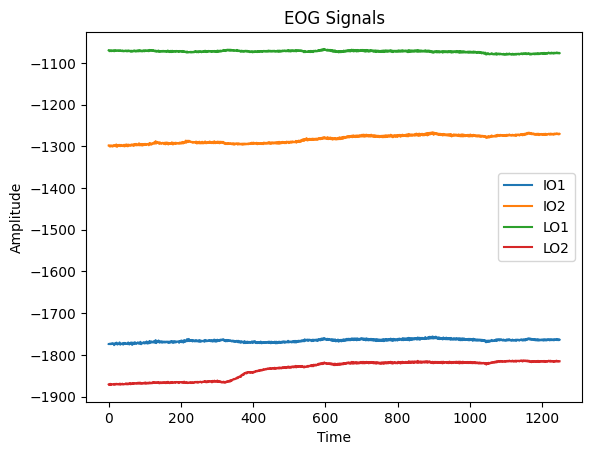

In [13]:
plt.plot(df_eog['IO1'].iloc[0:fs_eog*5], label='IO1')
plt.plot(df_eog['IO2'].iloc[0:fs_eog*5], label='IO2')
plt.plot(df_eog['LO1'].iloc[0:fs_eog*5], label='LO1')
plt.plot(df_eog['LO2'].iloc[0:fs_eog*5], label='LO2')

plt.xlabel('Time')
plt.ylabel('Amplitude')
plt.title('EOG Signals')
plt.legend()
plt.show()

Text(0.5, 0, 'Time')

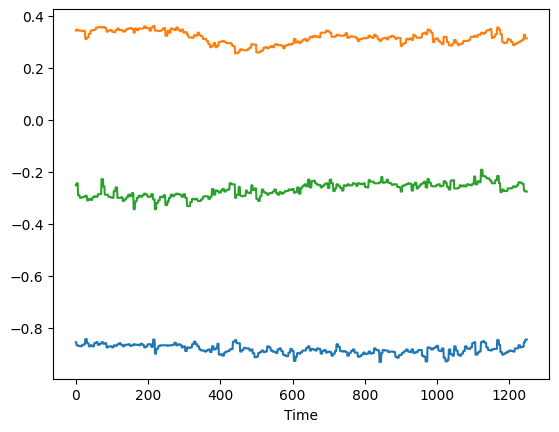

In [14]:
plt.plot(df_hm['Accel1'].iloc[0:fs_hm*5], label='Accel1')
plt.plot(df_hm['Accel2'].iloc[0:fs_hm*5], label='Accel2')
plt.plot(df_hm['Accel3'].iloc[0:fs_hm*5], label='Accel3')
plt.xlabel('Time')  

## Plotting Loaded Signals

### ECG and Rpeaks

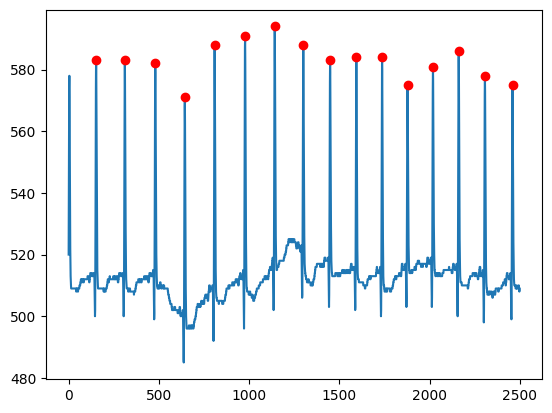

In [18]:
import numpy as np

i_strt = fs_ecg*0
i_end = fs_ecg*10

rpeak_samp = rpeak.ECG_R_Peaks.values[i_strt:i_end]
rpeak_idx = np.where(rpeak_samp == 1)[0]

plt.plot(ecg[i_strt:i_end])
plt.plot(rpeak_idx, ecg[i_strt:i_end][rpeak_idx], 'o', color = 'r')

### Respiration

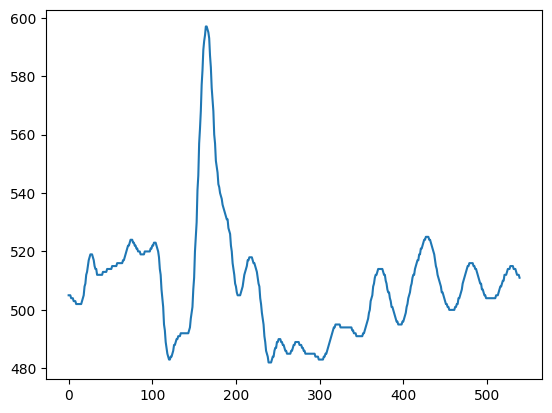

In [19]:
i_strt = fs_br*0
i_end = fs_br*30

plt.plot(br[i_strt:i_end])

### EEG

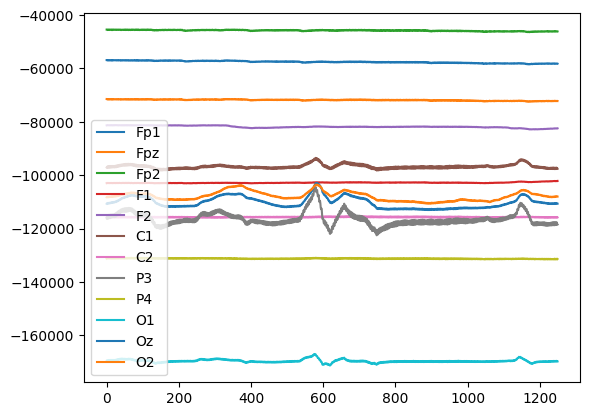

In [24]:
i_strt = fs_eeg*0
i_end = fs_eeg*5

plt.plot(df_eeg.iloc[i_strt:i_end])
plt.legend(df_eeg.columns)

# Load Features

In [ ]:
# create featureloader instance
featureloader = LoadExtractedFeatures(base_folder = '../sample_dataset/',
                           experiment='1_MW')

# load subject information you want to get data for
featureloader.load_subject_info(subject_id='S01', 
                             condition=1)


In [ ]:
base_folder = r'D:\Work\CSDataset\CSDatasetRaw_V1'
# create featureloader instance
featureloader = LoadExtractedFeatures(base_folder = base_folder,
                           experiment='1_MW')

# load subject information you want to get data for
featureloader.load_subject_info(subject_id='S01', 
                             phase=1)

In [7]:
df_eeg_feats = featureloader.get_features(feature_type='eeg')

df_hrv_feats = featureloader.get_features(feature_type='hrv')

df_br_feats = featureloader.get_features(feature_type='br')

In [8]:
df_hrv_feats

,hrv_time_median_rr,hrv_time_mean_rr,hrv_time_sdnn,hrv_time_rmssd,hrv_time_pnn50,hrv_time_pnn20,hrv_time_mean_abs_diff,rr_coverage
0,596.0,608.000000,37.929760,17.278692,0.000000,14.893617,12.510638,97.280000
1,588.0,587.440000,10.522661,8.533248,0.000000,2.040816,6.122449,97.906667
2,584.0,582.800000,10.770330,7.250616,0.000000,0.000000,5.469388,97.133333
3,576.0,577.098039,20.211873,8.447485,0.000000,4.000000,6.480000,98.106667
4,596.0,597.760000,33.620565,10.827026,0.000000,4.081633,8.408163,99.626667
5,624.0,627.148936,31.038054,14.673253,0.000000,15.217391,11.217391,98.253333
6,648.0,649.422222,26.801732,16.711455,0.000000,18.181818,13.272727,97.413333
7,656.0,649.688889,45.960283,21.641711,4.545455,31.818182,16.363636,97.453333
8,668.0,655.555556,51.461984,29.677050,11.363636,31.818182,19.818182,98.333333
9,656.0,657.422222,36.016347,27.309672,9.090909,29.545455,17.363636,98.613333
